In [18]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [19]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [20]:
#build vocabulary of characters and mappings to/from int
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [21]:

#set a blocksize i.e. how many characters will be considered at a time
blocksize = 3


######build the dataset WITH SPLITS
def build_dataset(words):

    #create an X and Y mapping arrays
    X, Y = [],[]
    
    #for every word
    
    for w in words:
        #create a context list of length blocksize
        context = [0]*blocksize
    
        for ch in w + '.':
            #get the index of the char
            ix = stoi[ch]
            #add the context that produced this char to X list
            X.append(context)
            
            #add the output (ix) to the Y list
            Y.append(ix)
            
            #crop and append the context
            context = context[1:]+[ix]
        #set X and Y to torch tensors
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

#split the dataset
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])



In [11]:
@torch.no_grad() # decorator disables gradient tracking
def split_loss(split):
    x,y = {
        'train':(Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte),
    }[split]
    
    emb = C[x] #embed inputs in feature vectors 
    embcat = emb.view(emb.shape[0], -1) # concat into (features, examples)
    hpreact = torch.tanh(embcat @ W1)
    hpreact = hpreact - bngain * bnmean_running / bnstd_running + bnbias #use _running mean and std for inference instead of calculating onthe fly

    logits = hpreact @ W2 + b2 # raw NN outputs ranging +- around 0
    loss = F.cross_entropy(logits, y) #softmax classification of logits, forward and backward much more efficient, fewer bugs
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.1709396839141846
val 2.2575743198394775


In [160]:
#let's train a deeper network

#class linear (layer)
class Linear:
    
    def __init__(self, fanin, fanout, bias=True):
        #init weights
        self.weight = torch.randn((fanin, fanout), generator = g) #/ fanin**0.5 
        #init biases
        self.bias = torch.zeros(fanout) if bias else None

    def __call__(self, x):
        #matmul weights with x
        self.out = x @ self.weight 
        #add bias
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

class BatchNorm1d:

    def __init__(self, dim, eps=1e-5, momentum = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        #parameters (trained with backprop)
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        #buffers
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps) #normalize unit variance
        self.out = self.gamma * xhat + self.beta 

        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
        
    def parameters(self):
        return []

#initialize network
n_embed = 10
n_hidden = 100
vocab_size = len(itos)

g = torch.Generator().manual_seed(2147483647)

C = torch.randn(vocab_size, n_embed, generator = g)

layers = [
    Linear(n_embed * blocksize, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, vocab_size), BatchNorm1d(vocab_size),
]

with torch.no_grad():
    layers[-1].gamma *= 0.1 #make last layer less confident
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 1 #5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # num params in total
for p in parameters:
    p.requires_grad = True


47551


In [161]:
#same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
ud = [] #update to data ratio

for i in range(max_steps):
    #minibatch construct
    ix = torch.randint(0,Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    #forward pass
    emb = C[Xb] #embed the characters into vectors
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) #loss function

    #backward pass
    for layer in layers:
        layer.out.retain_grad() #take out after debug
    for p in parameters:
        p.grad = None
    loss.backward()

    #update
    lr = 1.0#0.1 if i < max_steps*0.5 else 0.01
    for p in parameters:
        p.data += -lr*p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])

    if i > 1000:
        break #take this out to run full optimization

    #1:26:56

      0/ 200000: 3.2870


layer 2 (      Tanh): mean +0.02, std 0.63, saturated: 4.25%
layer 5 (      Tanh): mean -0.01, std 0.63, saturated: 3.06%
layer 8 (      Tanh): mean -0.02, std 0.64, saturated: 3.28%
layer 11 (      Tanh): mean -0.01, std 0.63, saturated: 3.09%
layer 14 (      Tanh): mean +0.02, std 0.64, saturated: 3.31%


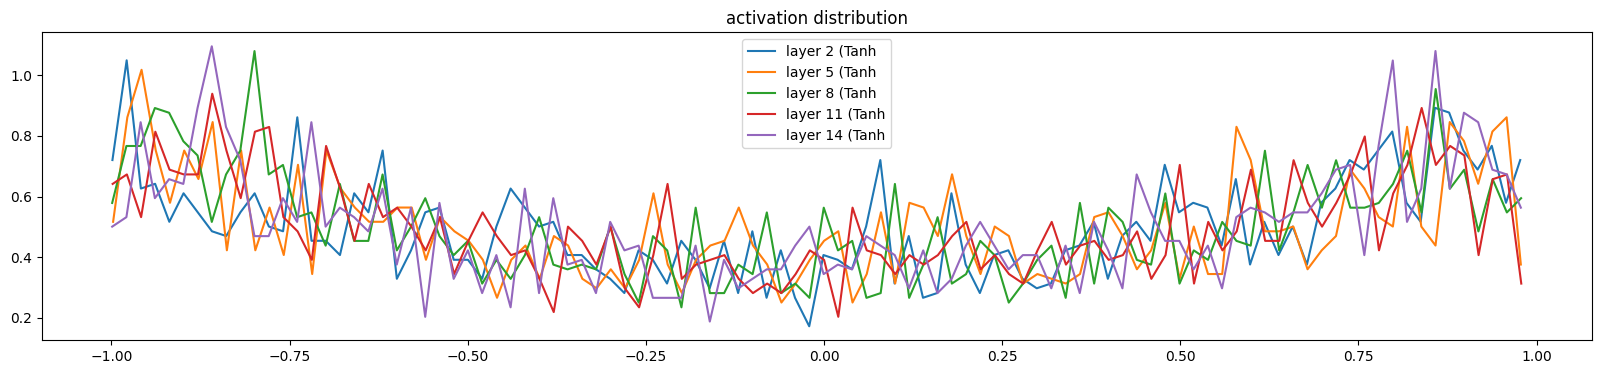

In [162]:
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers[:-1]): #excludes output layer
    if isinstance(layer, Tanh):
        t = layer.out
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() >0.97).float().mean()*100))
        hy, hx =torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__}')
    plt.legend(legends);
    plt.title('activation distribution')
        

layer 2 (      Tanh): mean +0.000000, std 4.360867e-03
layer 5 (      Tanh): mean -0.000000, std 3.804868e-03
layer 8 (      Tanh): mean -0.000000, std 3.511071e-03
layer 11 (      Tanh): mean +0.000000, std 3.270141e-03
layer 14 (      Tanh): mean +0.000000, std 3.144625e-03


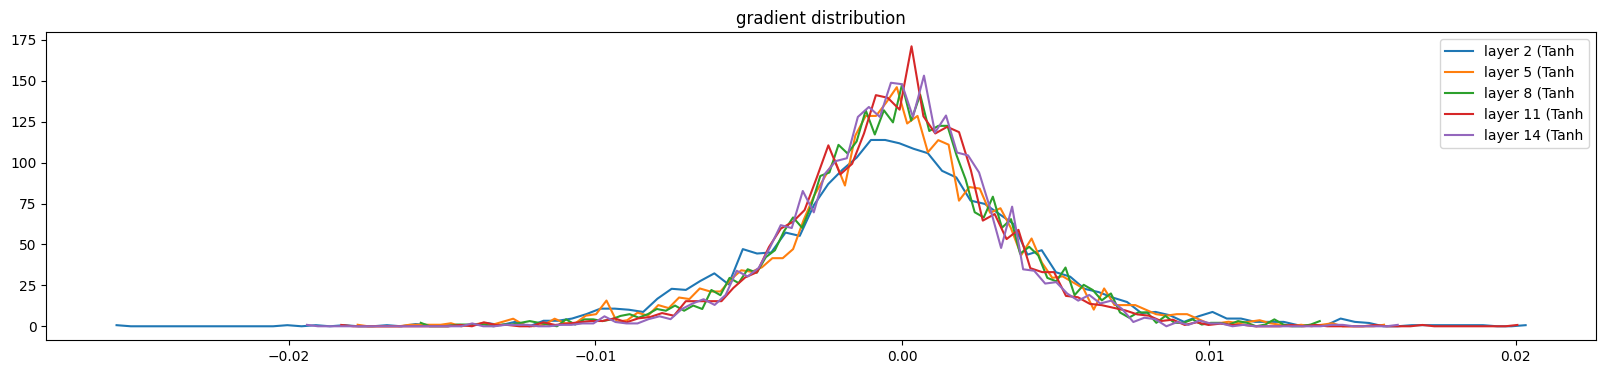

In [163]:
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers[:-1]): #excludes output layer
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
        hy, hx =torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__}')
    plt.legend(legends);
    plt.title('gradient distribution')
        

weight   (27, 10) | mean -0.000000 | std 8.547105e-03 | grad:data ratio 8.283905e-03
weight  (30, 100) | mean -0.000005 | std 2.678896e-03 | grad:data ratio 2.606680e-03
weight (100, 100) | mean +0.000026 | std 1.376784e-03 | grad:data ratio 1.380237e-03
weight (100, 100) | mean +0.000004 | std 1.260897e-03 | grad:data ratio 1.251008e-03
weight (100, 100) | mean +0.000012 | std 1.097643e-03 | grad:data ratio 1.093700e-03
weight (100, 100) | mean -0.000011 | std 1.066149e-03 | grad:data ratio 1.061357e-03
weight  (100, 27) | mean -0.000035 | std 1.968947e-03 | grad:data ratio 1.988357e-03


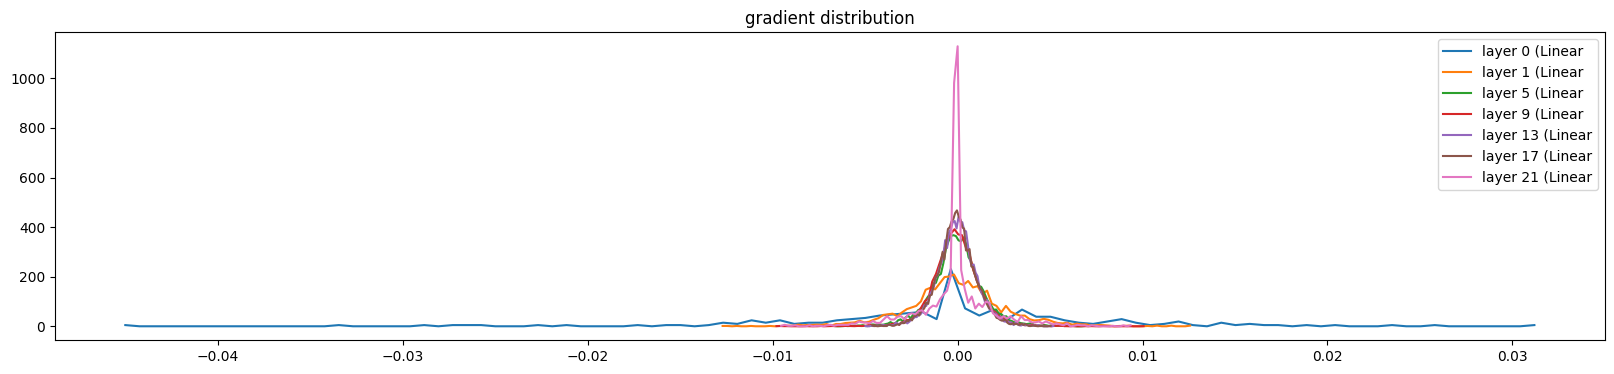

In [164]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters): 
    if p.ndim == 2:
        t = p.grad
        print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std()/p.std()))
        hy, hx =torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__}')
    plt.legend(legends);
    plt.title('gradient distribution')

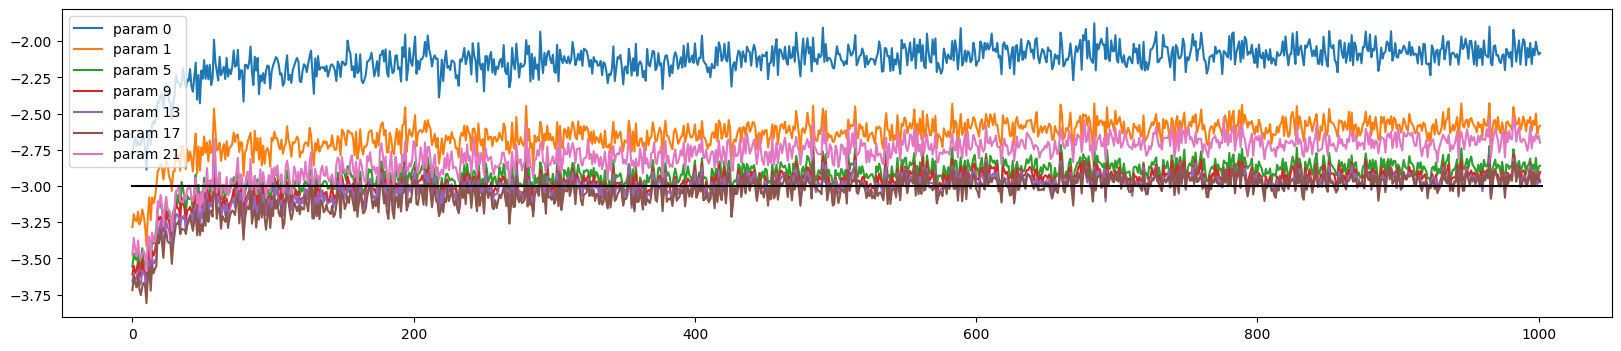

In [165]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters): 
    if p.ndim == 2:

        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios shoudl be ~1e-3, indicate on plot
plt.legend(legends);
    